<a href="https://colab.research.google.com/github/Juanma-dev-tech/AprendizajeAutomatico2/blob/main/TP1_AA2_Yacht_Hydrodynamics_PyTorch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP1 AA2 - Regresión con Redes Neuronales en PyTorch

**Juan Manuel Yñiguez**

Dataset: **Yacht Hydrodynamics**

---

## Estructura del notebook

Este notebook parte del **TP4 de Aprendizaje Automático I**, en el que se resolvió este problema mediante regresión lineal.

Para mantener como referencia el trabajo original, se conserva a continuación el desarrollo realizado en AA1.

***IMPORTANTE: El desarrollo correspondiente al TP1 de Aprendizaje Automático II comienza en la sección:***

### → TP1 AA2 - Implementación de la red neuronal en PyTorch

Allí se retoma el mismo dataset para entrenar una red neuronal, evaluar su desempeño, experimentar con distintas arquitecturas y comparar los resultados con los obtenidos en AA1.

# TP4 AA1

**Juan Manuel Yñiguez**

## Indicaciones básicas

0) Debe usar este notebook como template para su entrega. Haga una copia y comience a completar las consignas.

1) Cada uno debe completar las consignas indicadas en este notebook.

2)
3) No pueden repetir el mismo dataset que ya haya definido un compañero.

4) copias explícitas de secciones enteras del trabajo de otro será penalizado disminuyendo su puntuación.

5) No se olvide de añadir las fuentes de inspiración de su código (blogs, prompts de chatgpt o similar).

6) Además de todo el código que agregue, es importante que sepa interpretarlo. Agregue texto explicativo en cada sección. Esto le ayudará al momento del coloquio / parcial

7) Revise las fecha límite de entrega de este trabajo

# ENTREGA

* En el foro destinado a la tarea debe postear al menos tres veces:
  - La primera vez para indicar el dataset elegido
  - Una segunda vez para postear su entrega
  - Una tercera vez para brindar feedback a alguien más en el foro.
  - Puede comentar más de un posteo de sus compañeros siempre y cuando el intercambio sea respetuoso y fructífero.
* Deben postear como solución un enlace a su notebook colab público y también un enlace al mismo notebook alojado en su repositorio GitHub.
* Debe sumar el enlace a un video donde muestre su solución y explique lo realizado. Duración máxima: 5 - 10 minutos. Puede grabarse a Ud. mismo usando una sesión de zoom y grabar localmente. Puede subir el video a su youtube personal como privado o Unlisted.
* Enlaces no accesibles o enlaces erróneos es igual a determinar que la tarea no ha sido entregada. Corrobore la viabilidad de los enlaces que postea.


#**Tarea: Aplicación de Regresión Lineal y Análisis de Importancia de Variables**  
**Objetivo**: Aplicar un modelo de regresión lineal a un dataset de su elección, evaluar su rendimiento e identificar las variables más relevantes para la predicción.

---

# **Instrucciones**:

#1. **Selección del Dataset**  
   - Elijan un dataset de UCI ML Repository del siguiente enlace: https://archive.ics.uci.edu/datasets/?Task=Regression&skip=0&take=10&sort=desc&orderBy=NumHits&search=  
   - Requisitos:  
     - Debe tener al menos 4 variables numéricas continuas (1 target, 3 o más features).  
     - Idealmente, que las features tengan distintas escalas o unidades ( no excluyente).
     - Revisar en el foro de la tarea que dicho dataset no haya sido ya elegido por otra persona.
     - Postee en el foro de la tarea el dataset que eligió. Continue al siguiente punto.  



## Resolución:

In [ ]:
import pandas as pd
import requests
import zipfile
from io import BytesIO

url = "https://archive.ics.uci.edu/static/public/243/yacht+hydrodynamics.zip"

response = requests.get(url)

with zipfile.ZipFile(BytesIO(response.content)) as z:
    with z.open("yacht_hydrodynamics.data") as f:
        df = pd.read_csv(f, sep=r"\s+", header=None)

df.columns = [
    "Centro_Flotacion",
    "Coef_Prismatico",
    "Eslora_Desplazamiento",
    "Manga_Calado",
    "Eslora_Manga",
    "Numero_Froude",
    "Resistencia_Residual"
]

df.head()

,Centro_Flotacion,Coef_Prismatico,Eslora_Desplazamiento,Manga_Calado,Eslora_Manga,Numero_Froude,Resistencia_Residual
0,-2.3,0.568,4.78,3.99,3.17,0.125,0.11
1,-2.3,0.568,4.78,3.99,3.17,0.150,0.27
2,-2.3,0.568,4.78,3.99,3.17,0.175,0.47
3,-2.3,0.568,4.78,3.99,3.17,0.200,0.78
4,-2.3,0.568,4.78,3.99,3.17,0.225,1.18


### Descripción de las variables

El dataset Yacht Hydrodynamics contiene mediciones relacionadas con la geometría de embarcaciones a vela y parámetros de navegación.

Las variables utilizadas son:

- Centro_Flotacion: posición longitudinal del centro de flotación.
- Coef_Prismatico: coeficiente prismático del casco.
- Eslora_Desplazamiento: relación entre la eslora y el desplazamiento.
- Manga_Calado: relación entre la manga y el calado.
- Eslora_Manga: relación entre la eslora y la manga.
- Numero_Froude: número adimensional que relaciona la velocidad con la longitud característica de la embarcación.
- Resistencia_Residual: resistencia hidrodinámica residual por unidad de peso de desplazamiento (variable objetivo).


## 2. **Análisis exploratorio (previo al modelado)**  
   - Describan las variables (media, distribución, outliers).  
   - Visualizen:  
     - Histogramas o boxplots para ver distribuciones.  
     - Gráficos de dispersión (scatterplots) entre features y target.  
   - **Pregunta clave**: ¿Qué relaciones lineales preliminares observan?  


## Resolución:

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 308 entries, 0 to 307
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Centro_Flotacion       308 non-null    float64
 1   Coef_Prismatico        308 non-null    float64
 2   Eslora_Desplazamiento  308 non-null    float64
 3   Manga_Calado           308 non-null    float64
 4   Eslora_Manga           308 non-null    float64
 5   Numero_Froude          308 non-null    float64
 6   Resistencia_Residual   308 non-null    float64
dtypes: float64(7)
memory usage: 17.0 KB


### Estructura del dataset

A partir de la inspección inicial del dataset se observa que contiene 308 registros y 7 variables numéricas continuas. Todas las columnas fueron interpretadas correctamente como valores de tipo `float64`, por lo que no fue necesario realizar conversiones de tipo de dato antes de continuar con el análisis.


In [ ]:
df.describe()

,Centro_Flotacion,Coef_Prismatico,Eslora_Desplazamiento,Manga_Calado,Eslora_Manga,Numero_Froude,Resistencia_Residual
count,308.000000,308.000000,308.000000,308.000000,308.000000,308.000000,308.000000
mean,-2.381818,0.564136,4.788636,3.936818,3.206818,0.287500,10.495357
std,1.513219,0.023290,0.253057,0.548193,0.247998,0.100942,15.160490
min,-5.000000,0.530000,4.340000,2.810000,2.730000,0.125000,0.010000
25%,-2.400000,0.546000,4.770000,3.750000,3.150000,0.200000,0.777500
50%,-2.300000,0.565000,4.780000,3.955000,3.150000,0.287500,3.065000
75%,-2.300000,0.574000,5.100000,4.170000,3.510000,0.375000,12.815000
max,0.000000,0.600000,5.140000,5.350000,3.640000,0.450000,62.420000


### Estadísticas descriptivas

Las estadísticas descriptivas permiten conocer los valores promedio, la dispersión y los rangos de cada variable. Se observa que las variables presentan escalas diferentes. Por ejemplo, el coeficiente prismático toma valores cercanos a 0.5, mientras que la resistencia residual alcanza valores superiores a 60.

Estas diferencias de escala serán tenidas en cuenta durante la etapa de preprocesamiento mediante la aplicación de una técnica de normalización.


In [ ]:
df.isnull().sum()

,0
Centro_Flotacion,0
Coef_Prismatico,0
Eslora_Desplazamiento,0
Manga_Calado,0
Eslora_Manga,0
Numero_Froude,0
Resistencia_Residual,0


### Valores faltantes

No se detectaron valores faltantes en ninguna de las variables del dataset. Por este motivo, no fue necesario aplicar técnicas de imputación ni eliminar registros antes de continuar con el análisis.


### Distribución de las variables

Como parte del análisis exploratorio se estudió la distribución de cada variable mediante histogramas. Esto permite observar cómo se distribuyen los valores, identificar posibles asimetrías y detectar comportamientos inusuales en los datos.

Además, resulta útil para comprender las características generales del dataset antes de aplicar cualquier técnica de preprocesamiento o modelado.


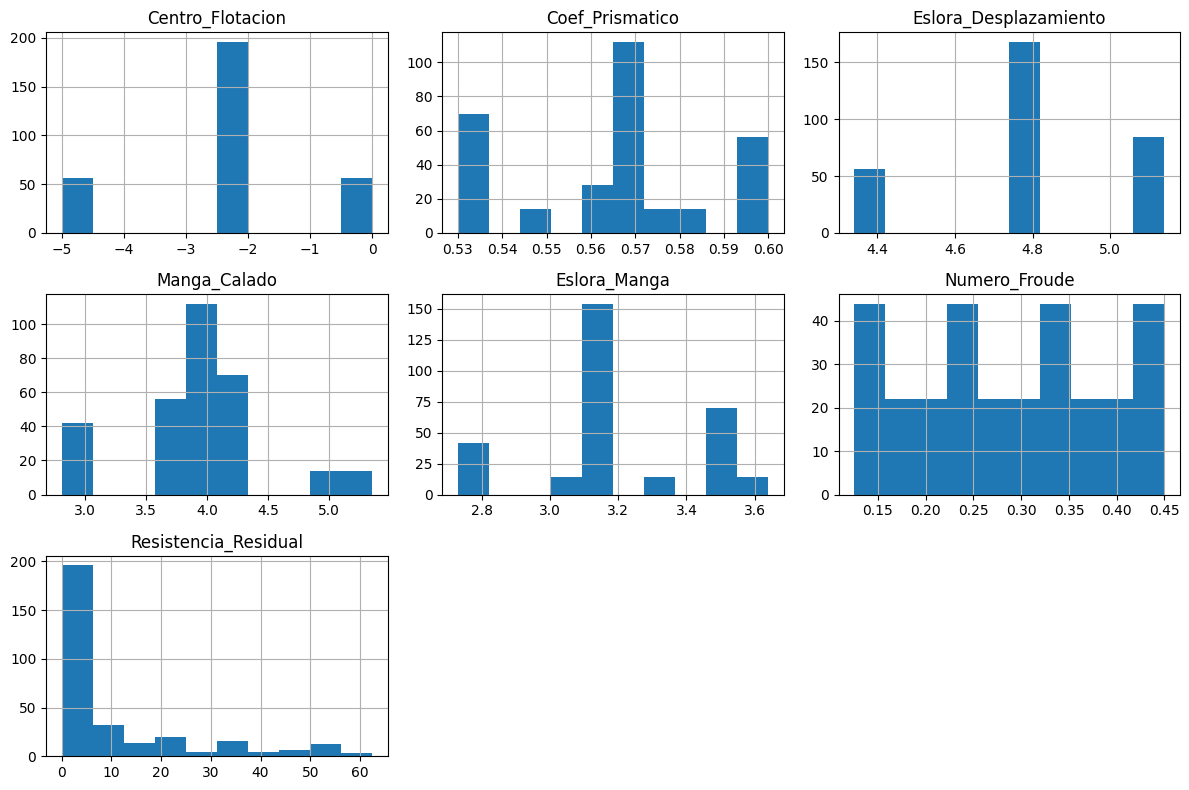

In [ ]:
import matplotlib.pyplot as plt

df.hist(figsize=(12,8))
plt.tight_layout()
plt.show()

### Observaciones sobre la distribución de las variables

A partir de los histogramas se observa que varias variables presentan valores concentrados en determinados rangos, lo que indica que algunas configuraciones de los yates aparecen con mayor frecuencia dentro del dataset.

También se aprecia que las variables no comparten la misma escala de valores. Mientras que algunas toman valores cercanos a 0 o 1, la variable objetivo `Resistencia_Residual` alcanza valores considerablemente mayores.

Por otro lado, la mayor parte de las observaciones de la variable objetivo se concentra en valores bajos, aunque existen algunos casos con resistencias significativamente más elevadas. Este comportamiento sugiere una distribución asimétrica que será analizada con mayor detalle mediante los diagramas de caja.


### Análisis de dispersión y valores atípicos

Luego de observar la distribución de las variables mediante histogramas, se utilizan diagramas de caja (boxplots) para complementar el análisis exploratorio.

Estos gráficos permiten visualizar la dispersión de los datos, comparar los rangos de cada variable e identificar posibles valores atípicos. Además, ayudan a determinar si será necesario aplicar algún tratamiento específico antes de entrenar el modelo.

Dado que la variable objetivo mostró una distribución concentrada en valores bajos y algunos valores considerablemente más elevados, resulta especialmente interesante verificar si existen observaciones que se apartan del comportamiento general del conjunto de datos.



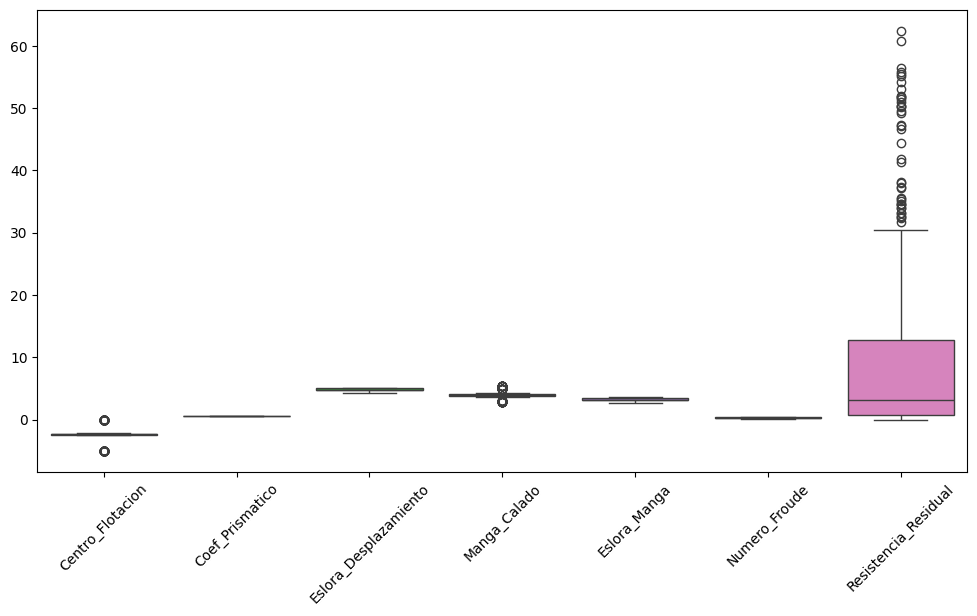

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))
sns.boxplot(data=df)
plt.xticks(rotation=45)
plt.show()

### Observaciones sobre los boxplots

Los diagramas de caja permiten observar la dispersión de las variables y detectar posibles valores atípicos.

Se aprecia que la variable objetivo `Resistencia_Residual` presenta una dispersión considerablemente mayor que el resto de las variables y una cantidad importante de observaciones por encima del rango principal de datos. Esto coincide con lo observado en los histogramas, donde la mayoría de los registros se concentraban en valores bajos y existían algunos casos con resistencias significativamente más elevadas.

También se observan algunos posibles valores atípicos en variables como `Centro_Flotacion` y `Manga_Calado`, aunque en menor medida.

Dado que el dataset representa mediciones obtenidas en experimentos hidrodinámicos reales, en esta etapa no se eliminarán dichos valores. Primero se evaluará el comportamiento del modelo utilizando la totalidad de los registros disponibles.


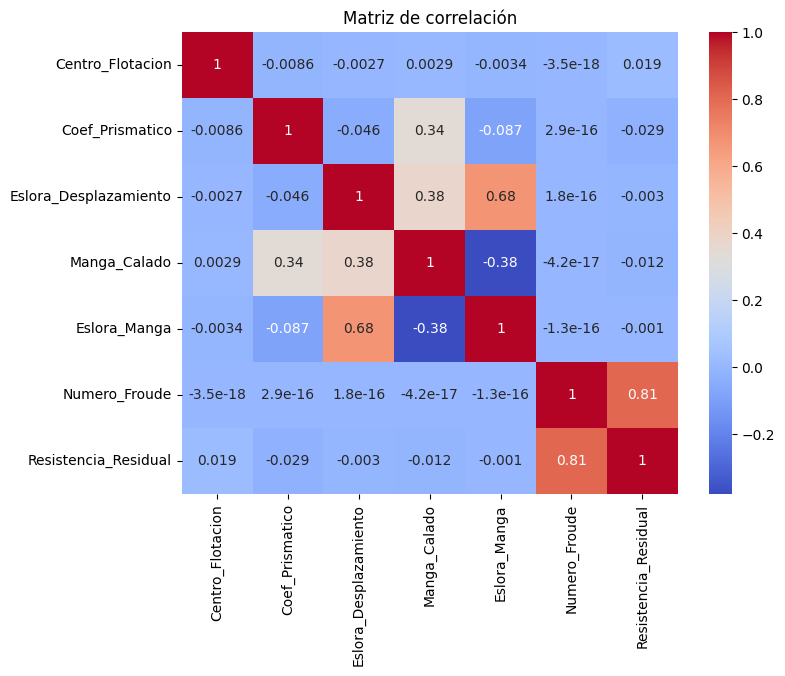

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.title("Matriz de correlación")
plt.show()

### Observaciones sobre la matriz de correlación

La matriz de correlación muestra que la variable `Numero_Froude` presenta una correlación positiva fuerte con la variable objetivo `Resistencia_Residual` (0.81), destacándose claramente sobre el resto de las variables.

Por el contrario, las demás variables exhiben correlaciones muy bajas con la resistencia residual, lo que sugiere una relación lineal débil o inexistente con el objetivo de predicción.

A partir de este análisis preliminar puede anticiparse que `Numero_Froude` tendrá un papel importante dentro del modelo de regresión lineal, ya que es la variable que muestra la asociación más fuerte con la variable objetivo.


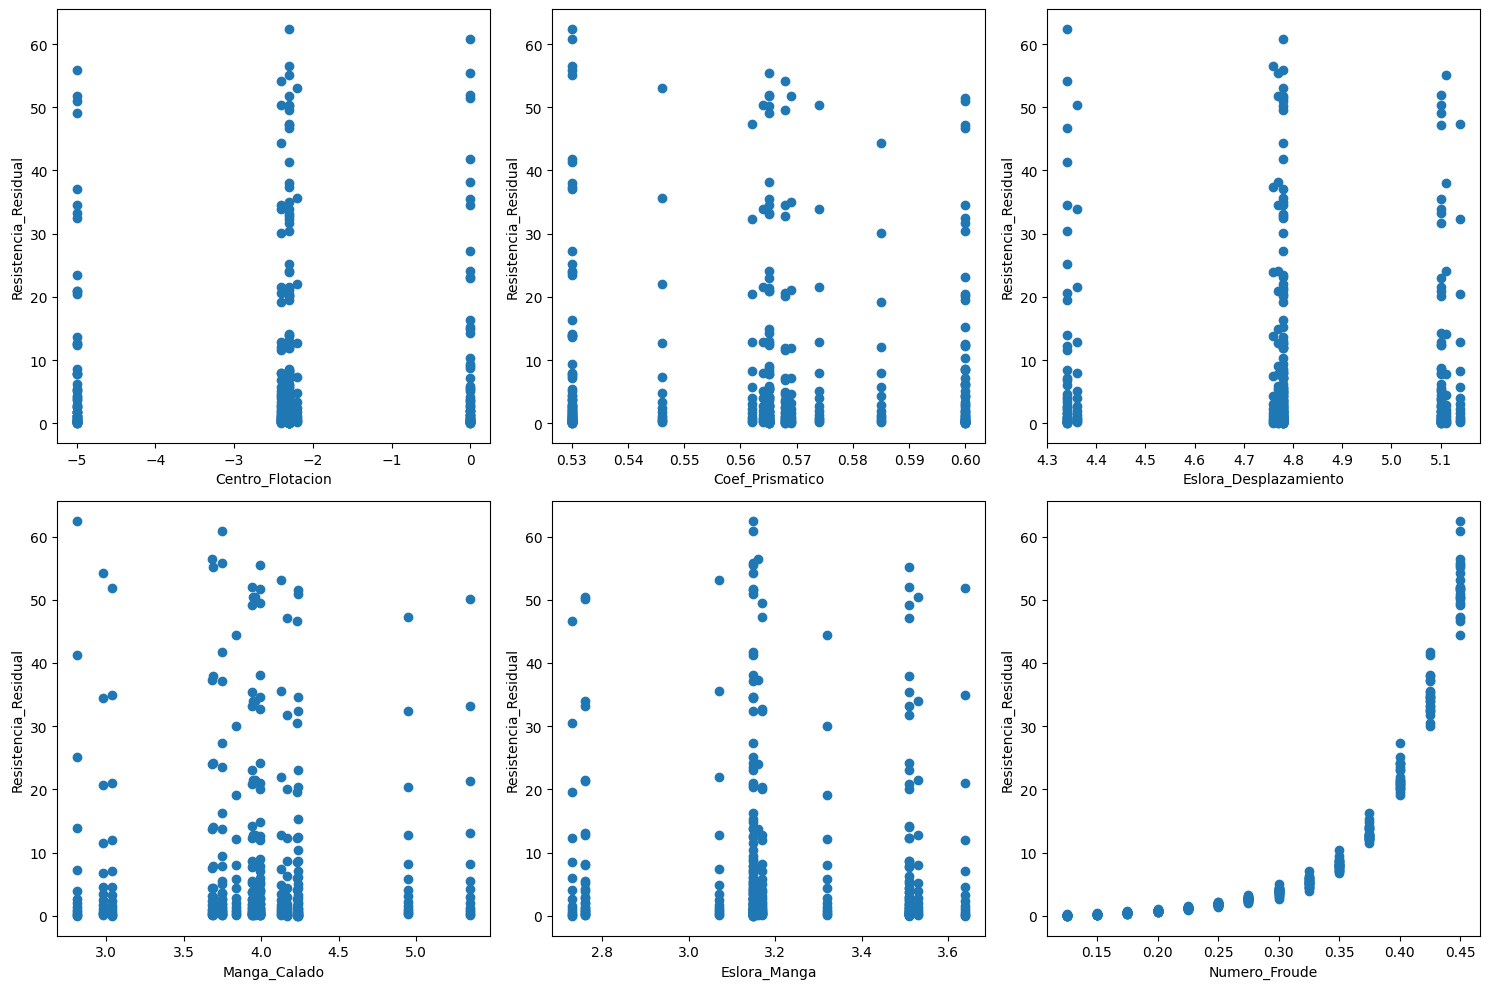

In [ ]:
features = df.columns[:-1]
target = "Resistencia_Residual"

fig, axes = plt.subplots(2, 3, figsize=(15,10))

for ax, feature in zip(axes.flatten(), features):
    ax.scatter(df[feature], df[target])
    ax.set_xlabel(feature)
    ax.set_ylabel(target)

plt.tight_layout()
plt.show()

### Observaciones finales del análisis exploratorio

Los gráficos de dispersión muestran que la mayoría de las variables presentan una relación débil con la variable objetivo `Resistencia_Residual`. En general, los puntos aparecen dispersos y no se observa una tendencia lineal claramente definida.

La excepción es `Numero_Froude`, donde se aprecia una relación positiva muy marcada con la resistencia residual. A medida que aumenta el valor de esta variable, la resistencia residual también tiende a incrementarse de forma significativa.

Esta observación coincide con los resultados obtenidos en la matriz de correlación, donde `Numero_Froude` presentó la asociación más fuerte con la variable objetivo. Por lo tanto, antes incluso de entrenar el modelo, existían indicios de que esta variable tendría una influencia importante en la capacidad predictiva de la regresión lineal.


## 3. **Preprocesamiento**  
   - Limpieza: Manejen missing values (eliminar, imputar) y outliers (si es necesario).  
   - Limpieza: indique cuáles features descarta. Justifique.
   - Indique si usará o no variables categóricas. Justifique. Realice su preprocesamiento adeucado.
   - Escalen las features (p.ej., StandardScaler) para comparar coeficientes después.  
   - Dividan en train/test (70-30 o 80-20).  

## Resolución:

## Preprocesamiento de los datos

Antes de entrenar el modelo se realiza una etapa de preprocesamiento para preparar los datos.

Durante el análisis exploratorio se verificó que el dataset no presenta valores faltantes. Asimismo, aunque se identificaron algunos posibles valores atípicos, se decidió conservarlos debido a que corresponden a mediciones reales obtenidas en experimentos hidrodinámicos.

Todas las variables disponibles son numéricas continuas, por lo que no es necesario aplicar técnicas de codificación para variables categóricas.

Además, se observó que las variables presentan diferentes escalas y rangos de valores. Por este motivo se utilizará StandardScaler para estandarizarlas antes del entrenamiento del modelo de regresión lineal.

Finalmente, los datos se dividirán en conjuntos de entrenamiento y prueba utilizando una proporción 80-20.

### Decisiones de preprocesamiento

-No se eliminaron registros del dataset.

-No fue necesario imputar valores faltantes.

-No se descartó ninguna variable, ya que todas representan características relevantes para el fenómeno físico estudiado.

-No se utilizaron variables categóricas porque el dataset está compuesto únicamente por variables numéricas continuas.

-Se aplicará estandarización mediante StandardScaler para llevar todas las variables a una escala comparable.

-Se utilizará una división 80% entrenamiento y 20% prueba para evaluar la capacidad de generalización del modelo.


### Estandarización de las variables

Las variables del dataset presentan diferentes escalas y rangos de valores. Para evitar que aquellas con valores numéricamente más grandes tengan una influencia desproporcionada durante el entrenamiento, se aplicará una estandarización mediante StandardScaler.

Esta técnica transforma cada variable para que tenga media cercana a 0 y desviación estándar cercana a 1, permitiendo trabajar con todas las variables en una escala comparable.

In [ ]:
from sklearn.preprocessing import StandardScaler

X = df.drop("Resistencia_Residual", axis=1)
y = df["Resistencia_Residual"]

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

X_scaled.head()

,Centro_Flotacion,Coef_Prismatico,Eslora_Desplazamiento,Manga_Calado,Eslora_Manga,Numero_Froude
0,0.054157,0.166162,-0.034184,0.097171,-0.148703,-1.612452
1,0.054157,0.166162,-0.034184,0.097171,-0.148703,-1.364382
2,0.054157,0.166162,-0.034184,0.097171,-0.148703,-1.116313
3,0.054157,0.166162,-0.034184,0.097171,-0.148703,-0.868243
4,0.054157,0.166162,-0.034184,0.097171,-0.148703,-0.620174


### Observaciones sobre la estandarización

Se observa que, luego de aplicar StandardScaler, las variables dejaron de expresarse en sus unidades originales y pasaron a una escala común. Los valores ahora se encuentran centrados alrededor de cero y expresados en términos de desviaciones estándar respecto de la media.

Esta transformación resulta útil porque permite comparar variables que originalmente tenían rangos diferentes y facilita la interpretación posterior de los coeficientes del modelo de regresión lineal.


### División de los datos en entrenamiento y prueba

Para evaluar la capacidad de generalización del modelo, los datos se dividirán en dos conjuntos.

El conjunto de entrenamiento será utilizado para ajustar el modelo de regresión lineal, mientras que el conjunto de prueba permitirá evaluar su rendimiento sobre observaciones que no fueron utilizadas durante el entrenamiento.

Se utilizará una proporción de 80% para entrenamiento y 20% para prueba.


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (246, 6)
X_test : (62, 6)
y_train: (246,)
y_test : (62,)


### Observaciones sobre la división de datos

Luego de la partición, el conjunto de entrenamiento quedó compuesto por 246 observaciones, mientras que el conjunto de prueba contiene 62 observaciones.

Esta división permitirá entrenar el modelo utilizando la mayor parte de los datos disponibles y, al mismo tiempo, evaluar su capacidad de generalización sobre datos no utilizados durante el entrenamiento.





## 4. **Regresión Lineal**  
   - Ajusten un modelo de regresión lineal (usando `sklearn.linear_model.LinearRegression`).  
   - Obtengan:  
     - Coeficientes (pesos) del modelo.  
     - Evaluar métricas en el set de entrenamiento y en el de testeo: **R²**, MSE (error cuadrático medio), MAE.  


## Entrenamiento del modelo de regresión lineal

Una vez finalizado el preprocesamiento de los datos, se procede a entrenar un modelo de regresión lineal utilizando las variables predictoras disponibles.

El objetivo es estimar la variable `Resistencia_Residual` a partir de las características geométricas de la embarcación y del número de Froude.

Posteriormente se evaluará el desempeño del modelo tanto sobre el conjunto de entrenamiento como sobre el conjunto de prueba mediante distintas métricas de regresión.


In [ ]:
from sklearn.linear_model import LinearRegression

modelo = LinearRegression()

modelo.fit(X_train, y_train)

LinearRegression()

In [ ]:
coeficientes = pd.DataFrame({
    "Variable": X.columns,
    "Coeficiente": modelo.coef_
})

coeficientes

,Variable,Coeficiente
0,Centro_Flotacion,0.597093
1,Coef_Prismatico,-0.246913
2,Eslora_Desplazamiento,-0.047135
3,Manga_Calado,-0.101274
4,Eslora_Manga,-0.071115
5,Numero_Froude,12.746088


### Evaluación del modelo

Una vez entrenado el modelo, se generan predicciones tanto sobre el conjunto de entrenamiento como sobre el conjunto de prueba.

Para evaluar el desempeño se utilizarán tres métricas:

* R²: indica qué proporción de la variabilidad de la variable objetivo es explicada por el modelo.
* MSE (Mean Squared Error): mide el error cuadrático medio de las predicciones.
* MAE (Mean Absolute Error): mide el error absoluto promedio entre los valores reales y los predichos.

La comparación entre entrenamiento y prueba permitirá analizar la capacidad de generalización del modelo.


In [ ]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Predicciones
y_train_pred = modelo.predict(X_train)
y_test_pred = modelo.predict(X_test)

# Métricas entrenamiento
r2_train = r2_score(y_train, y_train_pred)
mse_train = mean_squared_error(y_train, y_train_pred)
mae_train = mean_absolute_error(y_train, y_train_pred)

# Métricas prueba
r2_test = r2_score(y_test, y_test_pred)
mse_test = mean_squared_error(y_test, y_test_pred)
mae_test = mean_absolute_error(y_test, y_test_pred)

print("=== Entrenamiento ===")
print(f"R² : {r2_train:.4f}")
print(f"MSE: {mse_train:.4f}")
print(f"MAE: {mae_train:.4f}")

print("\n=== Prueba ===")
print(f"R² : {r2_test:.4f}")
print(f"MSE: {mse_test:.4f}")
print(f"MAE: {mae_test:.4f}")

=== Entrenamiento ===
R² : 0.6675
MSE: 81.6661
MAE: 7.4203

=== Prueba ===
R² : 0.5450
MSE: 67.6026
MAE: 6.8075


### Análisis de las métricas obtenidas

El modelo obtuvo un coeficiente de determinación (R²) de 0.6675 sobre el conjunto de entrenamiento y de 0.5450 sobre el conjunto de prueba. Esto indica que el modelo logra explicar una parte importante de la variabilidad de la resistencia residual, aunque todavía existe margen de mejora.

La diferencia entre ambos valores de R² no es excesiva, por lo que no se observan evidencias claras de sobreajuste. Esto sugiere que el modelo mantiene una capacidad razonable de generalización sobre datos no utilizados durante el entrenamiento.

Respecto a los errores, el MAE se mantiene cercano a 7 unidades tanto en entrenamiento como en prueba, mientras que el MSE presenta valores similares en ambos conjuntos. En conjunto, estos resultados indican que el modelo captura parte del comportamiento del fenómeno estudiado, aunque existen factores o relaciones que no están siendo completamente representados por una regresión lineal simple.



## 5. **Importancia de Variables**  
   - Analicen los **coeficientes** del modelo:  
     - Valores absolutos altos → mayor impacto en el target.  
     - Signo: Relación positiva/negativa con el target.  
   - Comparen la magnitud de los coeficientes **escalados** (si usaron features en distintas unidades).  
   - **5.1. Opcional**:
     Otra forma es "desordenar" un feature y ver cómo empeora el modelo. Si al desordenarlo el error aumenta mucho, ese feature era importante. Usen métodos como:  
     - **Permutation Importance** (de sklearn) para validar importancia. Más info en https://scikit-learn.org/stable/modules/permutation_importance.html



## Resolución:

## Importancia de las variables

Una de las ventajas de la regresión lineal es que permite interpretar la contribución de cada variable a la predicción realizada por el modelo.

Dado que las variables fueron previamente estandarizadas mediante StandardScaler, los coeficientes obtenidos pueden compararse directamente entre sí. Esto permite analizar qué variables tienen una mayor influencia sobre la resistencia residual y determinar si su relación con la variable objetivo es positiva o negativa.

En esta sección se estudiará la magnitud y el signo de los coeficientes para identificar las variables más relevantes dentro del modelo.


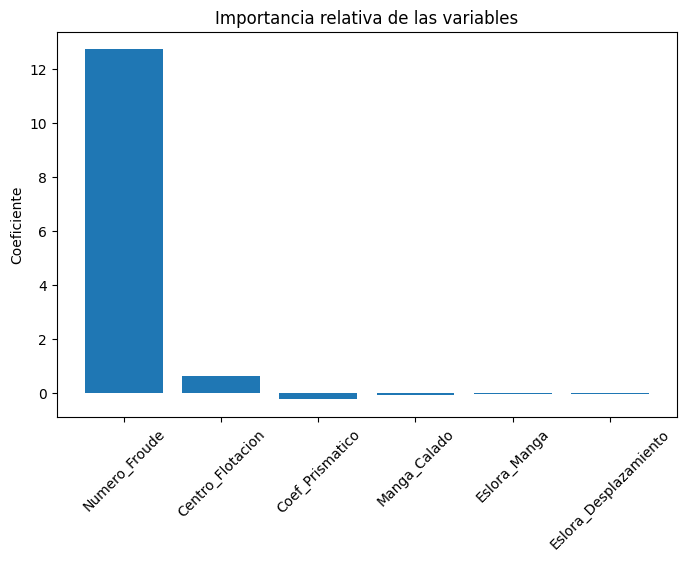

In [ ]:
import matplotlib.pyplot as plt

coeficientes_ordenados = coeficientes.sort_values(
    by="Coeficiente",
    key=abs,
    ascending=False
)

plt.figure(figsize=(8,5))
plt.bar(coeficientes_ordenados["Variable"],
        coeficientes_ordenados["Coeficiente"])
plt.xticks(rotation=45)
plt.ylabel("Coeficiente")
plt.title("Importancia relativa de las variables")
plt.show()

### Interpretación de los coeficientes

Al analizar la magnitud de los coeficientes obtenidos por el modelo se observa que `Numero_Froude` presenta el valor absoluto más alto, lo que indica que es la variable con mayor impacto sobre la predicción de la resistencia residual.

En segundo lugar aparece `Centro_Flotacion`, aunque con una influencia considerablemente menor. El resto de las variables presentan coeficientes de baja magnitud, lo que sugiere una contribución limitada dentro del modelo.

Respecto al signo de los coeficientes, los valores positivos indican que un aumento de la variable tiende a incrementar la resistencia residual estimada por el modelo, mientras que los coeficientes negativos indican una relación inversa.

Dado que todas las variables fueron previamente estandarizadas mediante StandardScaler, la comparación entre coeficientes resulta válida y permite evaluar directamente su importancia relativa.


### Relación con el análisis exploratorio

Los resultados obtenidos coinciden con las observaciones realizadas durante el análisis exploratorio.

Tanto la matriz de correlación como los gráficos de dispersión mostraban que `Numero_Froude` era la variable con la relación más fuerte respecto de `Resistencia_Residual`. Posteriormente, el modelo confirmó esta observación al asignarle el coeficiente de mayor magnitud.

Por el contrario, las demás variables presentaban correlaciones bajas y gráficos de dispersión sin tendencias lineales claras, situación que también se refleja en los coeficientes relativamente pequeños obtenidos por la regresión lineal.



## 6. **Reflexión**  
   - ¿Cuáles variables son más importantes según el modelo? ¿Coincide con su análisis exploratorio?  
   - ¿El modelo tiene buen rendimiento (R² alto, MSE bajo)? Si no, ¿a qué podría deberse?  



## Resolución:

## Reflexión

De acuerdo con los coeficientes obtenidos por el modelo, la variable más importante para la predicción de la resistencia residual es `Numero_Froude`, ya que presenta el coeficiente de mayor magnitud. En segundo lugar aparece `Centro_Flotacion`, aunque con una influencia considerablemente menor. El resto de las variables muestran una contribución reducida dentro del modelo.

Estos resultados coinciden con el análisis exploratorio realizado previamente. Tanto la matriz de correlación como los gráficos de dispersión mostraban que `Numero_Froude` era la variable con la relación más fuerte respecto de `Resistencia_Residual`, observación que posteriormente fue confirmada por el modelo de regresión lineal.

Respecto al rendimiento, el modelo obtuvo un R² de 0.6675 sobre el conjunto de entrenamiento y de 0.5450 sobre el conjunto de prueba. Esto indica que logra explicar una parte importante de la variabilidad de la resistencia residual, aunque todavía existe margen de mejora. La diferencia entre ambos valores no es excesiva, por lo que no se observan evidencias claras de sobreajuste.

El hecho de que el modelo no alcance valores más altos de R² podría deberse a que algunas relaciones presentes en los datos no son completamente lineales o a la existencia de factores que no están representados por las variables disponibles en el dataset. Aun así, los resultados obtenidos permiten concluir que la regresión lineal logra capturar una parte significativa del comportamiento del fenómeno estudiado.



## **Bonus**:  
- Prueben eliminar variables "poco importantes" y reentrenar el modelo. ¿Mejora el rendimiento?  

## Bonus: Eliminación de variables poco importantes

A partir del análisis de los coeficientes se observó que `Numero_Froude` concentra gran parte de la capacidad predictiva del modelo, mientras que varias variables presentan coeficientes de magnitud reducida.

Como experimento adicional, se entrenará un nuevo modelo utilizando únicamente las variables con mayor influencia para evaluar si es posible mantener o mejorar el rendimiento reduciendo la cantidad de variables utilizadas.


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Variables seleccionadas
X_reducido = df[["Numero_Froude", "Centro_Flotacion"]]
y = df["Resistencia_Residual"]

# Escalado
scaler = StandardScaler()
X_reducido_scaled = scaler.fit_transform(X_reducido)

# División
X_train_red, X_test_red, y_train_red, y_test_red = train_test_split(
    X_reducido_scaled,
    y,
    test_size=0.2,
    random_state=42
)

# Entrenamiento
modelo_red = LinearRegression()
modelo_red.fit(X_train_red, y_train_red)

# Predicciones
y_pred_red = modelo_red.predict(X_test_red)

# Métricas
r2_red = r2_score(y_test_red, y_pred_red)
mse_red = mean_squared_error(y_test_red, y_pred_red)
mae_red = mean_absolute_error(y_test_red, y_pred_red)

print(f"R² : {r2_red:.4f}")
print(f"MSE: {mse_red:.4f}")
print(f"MAE: {mae_red:.4f}")

R² : 0.5421
MSE: 68.0357
MAE: 6.8712


### Resultados del modelo reducido

Luego de entrenar un nuevo modelo utilizando únicamente `Numero_Froude` y `Centro_Flotacion`, se observa que las métricas obtenidas son muy similares a las del modelo original.

El coeficiente de determinación (R²) disminuyó levemente de 0.5450 a 0.5421, mientras que los errores MSE y MAE se mantuvieron prácticamente sin cambios.

Estos resultados sugieren que la mayor parte de la capacidad predictiva del modelo se encuentra concentrada en las variables `Numero_Froude` y `Centro_Flotacion`. Las variables restantes aportan información adicional limitada dentro de este problema de regresión.

Por lo tanto, la eliminación de las variables menos influyentes permitió simplificar el modelo sin afectar significativamente su rendimiento.



---

### **Tips**:  
- Si el R² es muy bajo, revisen si hay relaciones no lineales (y consideren transformar features).  
- Documenten cada paso: ¡la trazabilidad es clave en ciencia de datos!  
- Al final de su trabajo debe crear un apartado de REFERENCIAS para citar todo recurso utilizado. Si usó IA, debe


## Referencias

* UCI Machine Learning Repository. Yacht Hydrodynamics Dataset. https://archive.ics.uci.edu/dataset/243/yacht+hydrodynamics

* Scikit-learn Documentation. LinearRegression. https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html

* Scikit-learn Documentation. StandardScaler. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html

* Material de la asignatura Aprendizaje Automático I.

* Se utilizó ChatGPT como herramienta de apoyo para la interpretación de resultados, documentación del proceso y revisión de explicaciones teóricas.


# TP1 AA2 - Implementación de la red neuronal en PyTorch

A partir de esta sección comienza el desarrollo correspondiente a **Aprendizaje Automático II**.

## 1. Preparación de los datos para PyTorch

### Objetivo de esta sección

Para entrenar una red neuronal con PyTorch necesito reutilizar los datos preparados en el TP de Aprendizaje Automático I y convertirlos al formato que utiliza PyTorch.

La idea es mantener la misma división entre entrenamiento y test utilizada anteriormente, para que la comparación posterior entre la regresión lineal y la red neuronal sea lo más consistente posible.

En esta etapa voy a:

- reutilizar los datos de entrenamiento y test ya preparados;
- convertirlos a tensores de PyTorch;
- verificar sus dimensiones antes de construir la red neuronal.

In [ ]:
print(type(X_train))
print(type(y_train))
print(type(X_test))
print(type(y_test))

<class 'pandas.core.frame.DataFrame'>
<class 'pandas.core.series.Series'>
<class 'pandas.core.frame.DataFrame'>
<class 'pandas.core.series.Series'>


### Verificación previa

Antes de convertir los datos a tensores, verifiqué el tipo de las variables utilizadas en el TP original.

Los conjuntos `X_train` y `X_test` son `DataFrame` de pandas, mientras que `y_train` y `y_test` son `Series`.

Esta comprobación permitió confirmar que la conversión propuesta por Gemini mediante `.values` es compatible con las estructuras de datos actuales.

### Prompt utilizado en Gemini

> Estoy continuando un notebook de regresión realizado previamente con Scikit-learn. Ya tengo los conjuntos de entrenamiento y test preparados y escalados.
>
> Quiero comenzar una implementación de regresión con PyTorch.
>
> Ayudame únicamente con esta primera etapa:
> 1. importar PyTorch;
> 2. convertir mis datos de entrenamiento y test a tensores `float32`;
> 3. asegurar que la variable objetivo tenga una forma compatible con una salida de regresión de una sola neurona;
> 4. mostrar las dimensiones (`shape`) de los tensores resultantes para verificarlas.
>
> No construyas todavía la red neuronal, no definas `nn.Module`, no entrenes el modelo y no agregues `DataLoader`.
>
> Explicá brevemente qué hace cada parte del código.

In [ ]:
import torch

# Convertir los DataFrames y Series de pandas a tensores de PyTorch
# Se utiliza .values para obtener los arrays de NumPy subyacentes antes de la conversión a tensor.
# Se especifica dtype=torch.float32 para asegurar la precisión requerida por PyTorch para modelos de red neuronal.
X_train_tensor = torch.tensor(X_train.values, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test.values, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32)

# Asegurar que la variable objetivo (y_train_tensor, y_test_tensor) tenga la forma (N, 1)
# Esto es crucial para la regresión con una sola neurona de salida, ya que PyTorch espera
# que la variable objetivo tenga esta forma para el cálculo de la pérdida.
y_train_tensor = y_train_tensor.view(-1, 1)
y_test_tensor = y_test_tensor.view(-1, 1)

# Mostrar las dimensiones (shape) de los tensores resultantes para verificarlas
# Esto permite confirmar que los datos se han convertido y moldeado correctamente
# antes de proceder con la construcción del modelo.
print("Shape de X_train_tensor:", X_train_tensor.shape)
print("Shape de y_train_tensor:", y_train_tensor.shape)
print("Shape de X_test_tensor:", X_test_tensor.shape)
print("Shape de y_test_tensor:", y_test_tensor.shape)

Shape de X_train_tensor: torch.Size([246, 6])
Shape de y_train_tensor: torch.Size([246, 1])
Shape de X_test_tensor: torch.Size([62, 6])
Shape de y_test_tensor: torch.Size([62, 1])


### Verificación de dimensiones

Luego de convertir los datos a tensores, se obtuvieron las siguientes dimensiones:

- `X_train_tensor`: 246 muestras y 6 variables de entrada.
- `y_train_tensor`: 246 valores objetivo.
- `X_test_tensor`: 62 muestras y 6 variables de entrada.
- `y_test_tensor`: 62 valores objetivo.

La dimensión de salida `(N, 1)` es compatible con un problema de regresión con una única variable objetivo.

## 2. Definición de la arquitectura de la red neuronal

Como el problema tiene 6 variables de entrada y una única variable objetivo, se propone inicialmente una red neuronal sencilla con la siguiente estructura:

**6 → 8 → 4 → 1**

La red tendrá dos capas ocultas de 8 y 4 neuronas respectivamente, utilizando `ReLU` como función de activación entre ellas.

La capa de salida tendrá una sola neurona y no utilizará función de activación, ya que se trata de un problema de regresión y se necesita predecir un valor continuo.

Se eligió una arquitectura de tamaño moderado porque el conjunto de entrenamiento es relativamente pequeño. Esta configuración servirá además como punto de partida para luego experimentar con redes más simples y más complejas y analizar situaciones de underfitting y overfitting.

### Prompt utilizado en Gemini

>Tengo un problema de regresión con 6 variables de entrada y una sola variable >objetivo.
>
>Ya convertí mis datos de entrenamiento y test a tensores de PyTorch.
>
>Quiero definir únicamente la arquitectura inicial de la red neuronal.
>
>Creá una clase que herede de nn.Module con esta arquitectura:
>6 entradas → 8 neuronas → 4 neuronas → 1 salida.
>
>Usá ReLU entre las capas ocultas y no uses función de activación en la capa de >salida porque se trata de un problema de regresión.
>
>Definí correctamente __init__ y forward.
>
>No entrenes todavía la red, no definas función de pérdida, optimizador ni >épocas.
>
>Explicá brevemente qué hace cada parte del código.

In [ ]:
import torch.nn as nn # Importa el módulo neural network de PyTorch

# Define la clase NeuralNetwork que hereda de nn.Module
# Esto permite a la clase aprovechar la funcionalidad predefinida de PyTorch para redes neuronales
class NeuralNetwork(nn.Module):
    def __init__(self):
        super(NeuralNetwork, self).__init__() # Llama al constructor de la clase base nn.Module
        # Define las capas de la red neuronal
        # nn.Linear crea una capa densa (fully connected) con un número específico de entradas y salidas
        self.fc1 = nn.Linear(6, 8)  # Capa de entrada (6 características) a la primera capa oculta (8 neuronas)
        self.fc2 = nn.Linear(8, 4)  # Primera capa oculta (8 neuronas) a la segunda capa oculta (4 neuronas)
        self.fc3 = nn.Linear(4, 1)  # Segunda capa oculta (4 neuronas) a la capa de salida (1 neurona para regresión)

    def forward(self, x):
        # Define el paso hacia adelante de la red neuronal
        # Aplica la función de activación ReLU a la salida de las capas ocultas
        # ReLU (Rectified Linear Unit) es una función de activación no lineal que introduce complejidad al modelo.
        x = torch.relu(self.fc1(x)) # Pasa los datos por la primera capa y aplica ReLU
        x = torch.relu(self.fc2(x)) # Pasa los datos por la segunda capa y aplica ReLU
        x = self.fc3(x)           # Pasa los datos por la capa de salida sin función de activación (para regresión)
        return x

In [ ]:
torch.manual_seed(42)

model = NeuralNetwork()
print(model)

NeuralNetwork(
  (fc1): Linear(in_features=6, out_features=8, bias=True)
  (fc2): Linear(in_features=8, out_features=4, bias=True)
  (fc3): Linear(in_features=4, out_features=1, bias=True)
)


### Verificación de la arquitectura

La instancia creada confirma que la red respeta la estructura definida previamente: **6 → 8 → 4 → 1**.

Antes de comenzar el entrenamiento, voy a realizar una prueba con algunas muestras del conjunto de entrenamiento para verificar que el `forward` procese correctamente los datos y que la salida tenga la dimensión esperada.

En esta prueba todavía no se evalúa la calidad de las predicciones, ya que los pesos de la red se encuentran inicializados aleatoriamente.

In [ ]:
with torch.no_grad():
    pred_prueba = model(X_train_tensor[:5])

print(pred_prueba)
print(pred_prueba.shape)

tensor([[0.3551],
        [0.3990],
        [0.4627],
        [0.2494],
        [0.3998]])
torch.Size([5, 1])


### Resultado de la verificación

La prueba del `forward` devolvió una salida con dimensión `torch.Size([5, 1])`.

Esto confirma que la red procesa correctamente las muestras de entrada y genera una única predicción por observación, como corresponde al problema de regresión planteado.

Los valores obtenidos todavía no representan predicciones útiles, ya que la red aún no fue entrenada y sus pesos se encuentran inicializados aleatoriamente.

## 3. Entrenamiento de la red neuronal

Una vez definida y verificada la arquitectura, el siguiente paso es entrenar la red para que pueda ajustar sus pesos a partir de los datos de entrenamiento.

Para esta etapa será necesario definir:

- una función de pérdida que permita medir qué tan lejos están las predicciones de los valores reales;
- un optimizador encargado de actualizar los pesos de la red;
- una cantidad de épocas de entrenamiento;
- el ciclo de entrenamiento compuesto por `zero_grad()`, `forward`, cálculo de la pérdida, `backward()` y `step()`.

Durante el entrenamiento también se registrará la pérdida de cada época para poder analizar posteriormente cómo evoluciona el aprendizaje del modelo.

En esta primera configuración se entrenará únicamente la arquitectura base **6 → 8 → 4 → 1**. Más adelante se modificarán la cantidad de neuronas y/o capas para analizar situaciones de underfitting y overfitting.

### Prompt utilizado en Gemini

> Ya tengo definida e instanciada una red neuronal de regresión en PyTorch con arquitectura **6 → 8 → 4 → 1**.
>
> Los datos ya están convertidos a tensores `float32`:
>
> - `X_train_tensor`
> - `y_train_tensor`
> - `X_test_tensor`
> - `y_test_tensor`
>
> Quiero trabajar únicamente sobre el **entrenamiento de la red base**.
>
> Necesito que:
>
> 1. definas una función de pérdida adecuada para un problema de regresión;
> 2. definas un optimizador para actualizar los parámetros de `model`;
> 3. establezcas una cantidad razonable de épocas para una primera prueba;
> 4. implementes un ciclo de entrenamiento que incluya explícitamente:
>    - `optimizer.zero_grad()`
>    - forward pass
>    - cálculo de la pérdida
>    - `loss.backward()`
>    - `optimizer.step()`
> 5. guardes la pérdida de entrenamiento de cada época en una lista para analizarla posteriormente;
> 6. muestres la pérdida cada cierta cantidad de épocas para poder seguir la evolución del entrenamiento.
>
> No calcules todavía métricas sobre test, no hagas gráficos, no pruebes otras arquitecturas y no agregues `DataLoader`.
>
> Explicá brevemente por qué elegiste esa función de pérdida, ese optimizador y esos hiperparámetros.

In [ ]:
# 1. Definir la función de pérdida
# Para problemas de regresión, el Mean Squared Error (MSE) es una elección común y efectiva.
# Mide el promedio de los cuadrados de los errores, es decir, la diferencia cuadrada promedio
# entre los valores estimados y los valores reales. Esto penaliza más los errores grandes.
criterion = nn.MSELoss()

# 2. Definir el optimizador
# Adam adapta la actualización de los parámetros utilizando información
# de los gradientes calculados durante el entrenamiento.
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# 3. Establecer la cantidad de épocas
# 1000 épocas es una cantidad razonable para una primera prueba en un dataset pequeño.
# Luego se analizará la evolución de la pérdida para evaluar si esta cantidad fue suficiente o excesiva.
n_epochs = 1000

# Lista para guardar las pérdidas de entrenamiento de cada época
losses = []

# 4. Implementar el ciclo de entrenamiento
for epoch in range(n_epochs):
    # Poner los gradientes a cero para evitar acumulación de los cálculos de la época anterior.
    # Esto es crucial en PyTorch para cada iteración del entrenamiento.
    optimizer.zero_grad()

    # Forward pass: calcular las predicciones del modelo para los datos de entrenamiento.
    y_pred = model(X_train_tensor)

    # Calcular la pérdida: comparar las predicciones con los valores reales.
    loss = criterion(y_pred, y_train_tensor)

    # Backward pass: calcular los gradientes de la pérdida con respecto a los parámetros del modelo.
    loss.backward()

    # Actualizar los pesos del modelo utilizando el optimizador.
    optimizer.step()

    # Guardar la pérdida de entrenamiento
    losses.append(loss.item())

    # 6. Mostrar la pérdida cada cierta cantidad de épocas (por ejemplo, cada 100 épocas)
    if (epoch + 1) % 100 == 0:
        print(f'Epoch {epoch+1}/{n_epochs}, Loss: {loss.item():.4f}')

print('\nEntrenamiento completado.')

Epoch 100/1000, Loss: 355.0430
Epoch 200/1000, Loss: 320.0081
Epoch 300/1000, Loss: 251.6652
Epoch 400/1000, Loss: 162.2219
Epoch 500/1000, Loss: 103.7345
Epoch 600/1000, Loss: 74.7240
Epoch 700/1000, Loss: 59.0681
Epoch 800/1000, Loss: 47.9612
Epoch 900/1000, Loss: 40.1544
Epoch 1000/1000, Loss: 34.1036

Entrenamiento completado.


### Evolución inicial del entrenamiento

La pérdida de entrenamiento disminuyó de manera sostenida a lo largo de las 1000 épocas, pasando de valores superiores a 300 hasta aproximadamente 34.

Esto indica que la red logró ajustar progresivamente sus parámetros sobre los datos de entrenamiento.

Sin embargo, esta disminución por sí sola no permite determinar si el modelo generaliza correctamente. Para eso es necesario evaluar su desempeño sobre el conjunto de test y comparar ambas métricas.

## 4. Evaluación del modelo en entrenamiento y test

Una vez finalizado el entrenamiento de la red base, es necesario evaluar su desempeño tanto sobre los datos utilizados para entrenar como sobre el conjunto de test.

Para mantener la comparación con el trabajo realizado en Aprendizaje Automático I, se calcularán las mismas métricas principales:

- **MSE**: error cuadrático medio.
- **MAE**: error absoluto medio.
- **R²**: proporción de variabilidad explicada por el modelo.

La comparación entre entrenamiento y test permitirá observar no solo la calidad de las predicciones, sino también si existe una diferencia importante entre ambos conjuntos.

### Prompt utilizado en Gemini

> Ya entrené una red neuronal de regresión en PyTorch con arquitectura **6 → 8 → 4 → 1**.
>
> Tengo disponibles:
>
> - `model`
> - `X_train_tensor`
> - `y_train_tensor`
> - `X_test_tensor`
> - `y_test_tensor`
>
> Quiero evaluar únicamente el modelo ya entrenado.
>
> Necesito que:
>
> 1. pongas el modelo en modo evaluación con `model.eval()`;
> 2. generes predicciones para entrenamiento y test sin calcular gradientes;
> 3. calcules **MSE**, **MAE** y **R²** para ambos conjuntos;
> 4. muestres los resultados de forma clara para poder compararlos.
>
> Podés utilizar funciones de `sklearn.metrics` si resulta conveniente, convirtiendo los tensores a NumPy cuando sea necesario.
>
> No hagas todavía gráficos, no entrenes nuevamente el modelo y no pruebes otras arquitecturas.
>
> Explicá brevemente qué representa cada métrica y por qué es útil comparar sus valores entre entrenamiento y test.

In [ ]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# 1. Poner el modelo en modo evaluación.
# Aunque esta arquitectura no utiliza Dropout ni BatchNorm,
# es una buena práctica indicar explícitamente que el modelo será evaluado.
model.eval()

# 2. Generar predicciones para entrenamiento y test sin calcular gradientes
# torch.no_grad() desactiva el cálculo de gradientes, lo que reduce el consumo de memoria
# y acelera las inferencias, ya que no son necesarios durante la evaluación.
with torch.no_grad():
    y_train_pred_tensor = model(X_train_tensor)
    y_test_pred_tensor = model(X_test_tensor)

# Convertir los tensores de PyTorch a arrays de NumPy para usar sklearn.metrics
# .cpu().numpy() asegura que el tensor esté en la CPU y luego lo convierte a NumPy.
y_train_pred = y_train_pred_tensor.cpu().numpy()
y_test_pred = y_test_pred_tensor.cpu().numpy()
y_train_np = y_train_tensor.cpu().numpy()
y_test_np = y_test_tensor.cpu().numpy()

# 3. Calcular MSE, MAE y R² para ambos conjuntos

# Métricas para el conjunto de entrenamiento
mse_train_pt = mean_squared_error(y_train_np, y_train_pred)
mae_train_pt = mean_absolute_error(y_train_np, y_train_pred)
r2_train_pt = r2_score(y_train_np, y_train_pred)

# Métricas para el conjunto de prueba
mse_test_pt = mean_squared_error(y_test_np, y_test_pred)
mae_test_pt = mean_absolute_error(y_test_np, y_test_pred)
r2_test_pt = r2_score(y_test_np, y_test_pred)

# 4. Mostrar los resultados
print("=== Métricas de PyTorch (Entrenamiento) ===")
print(f"MSE (Entrenamiento): {mse_train_pt:.4f}")
print(f"MAE (Entrenamiento): {mae_train_pt:.4f}")
print(f"R² (Entrenamiento) : {r2_train_pt:.4f}")

print("\n=== Métricas de PyTorch (Prueba) ===")
print(f"MSE (Prueba): {mse_test_pt:.4f}")
print(f"MAE (Prueba): {mae_test_pt:.4f}")
print(f"R² (Prueba) : {r2_test_pt:.4f}")

print("\n=== Explicación de las Métricas ===")
print("• MSE (Error Cuadrático Medio): Mide el promedio de los cuadrados de los errores. Penaliza fuertemente los errores grandes.")
print("• MAE (Error Absoluto Medio): Mide el promedio de los valores absolutos de los errores. Es menos sensible a los outliers que el MSE.")
print("• R² (Coeficiente de Determinación): Indica qué proporción de la variabilidad de la variable objetivo es explicada por el modelo. Cuanto más cercano a 1, mejor es el ajuste.")
print("\nEs útil comparar los valores de estas métricas entre el conjunto de entrenamiento y el de prueba para detectar sobreajuste (overfitting) o subajuste (underfitting). Si el desempeño es pobre tanto en entrenamiento como en prueba, el modelo podría estar subajustado.")

=== Métricas de PyTorch (Entrenamiento) ===
MSE (Entrenamiento): 34.0475
MAE (Entrenamiento): 4.3770
R² (Entrenamiento) : 0.8614

=== Métricas de PyTorch (Prueba) ===
MSE (Prueba): 28.9248
MAE (Prueba): 3.6631
R² (Prueba) : 0.8053

=== Explicación de las Métricas ===
• MSE (Error Cuadrático Medio): Mide el promedio de los cuadrados de los errores. Penaliza fuertemente los errores grandes.
• MAE (Error Absoluto Medio): Mide el promedio de los valores absolutos de los errores. Es menos sensible a los outliers que el MSE.
• R² (Coeficiente de Determinación): Indica qué proporción de la variabilidad de la variable objetivo es explicada por el modelo. Cuanto más cercano a 1, mejor es el ajuste.

Es útil comparar los valores de estas métricas entre el conjunto de entrenamiento y el de prueba para detectar sobreajuste (overfitting) o subajuste (underfitting). Si el desempeño es pobre tanto en entrenamiento como en prueba, el modelo podría estar subajustado.


### Interpretación de los resultados

La red neuronal base obtuvo un R² de **0.8614** en entrenamiento y de **0.8053** en test.

La diferencia entre ambos valores es moderada, por lo que en esta configuración no se observa un sobreajuste marcado. El modelo mantiene un buen desempeño sobre datos no utilizados durante el entrenamiento.

Además, los errores obtenidos en test fueron:

- MSE: **28.9248**
- MAE: **3.6631**

Estos resultados muestran una mejora respecto de la regresión lineal utilizada en Aprendizaje Automático I, lo que sugiere que la red neuronal puede representar relaciones no lineales presentes en los datos que el modelo lineal no conseguía capturar completamente.

Sin embargo, esta es solamente la arquitectura base. A continuación se realizarán experimentos modificando la cantidad de neuronas y/o capas para analizar situaciones de underfitting y overfitting.

## 5. Experimentación: underfitting y overfitting

Para analizar cómo influye la capacidad de la red neuronal en su desempeño, se compararán distintas arquitecturas manteniendo constantes el resto de las condiciones de entrenamiento.

Se utilizarán tres configuraciones:

- **Red simple:** 6 → 2 → 1
- **Red base:** 6 → 8 → 4 → 1
- **Red compleja:** 6 → 32 → 16 → 8 → 1

En todos los casos se mantendrán el mismo conjunto de entrenamiento y test, la misma semilla, la función de pérdida MSE, el optimizador Adam y la misma cantidad de épocas.

Durante el entrenamiento se registrará la pérdida tanto sobre entrenamiento como sobre test en cada época. Luego se compararán las curvas para identificar posibles situaciones de underfitting, buen ajuste y overfitting.

### Prompt utilizado en Gemini

> Ya tengo preparados los tensores:
>
> - `X_train_tensor`
> - `y_train_tensor`
> - `X_test_tensor`
> - `y_test_tensor`
>
> Quiero realizar un experimento controlado para analizar **underfitting y overfitting** en un problema de regresión con PyTorch.
>
> Voy a comparar estas tres arquitecturas:
>
> - red simple: **6 → 2 → 1**
> - red base: **6 → 8 → 4 → 1**
> - red compleja: **6 → 32 → 16 → 8 → 1**
>
> Necesito que:
>
> 1. definas las tres arquitecturas como clases que hereden de `nn.Module`;
> 2. uses `ReLU` en las capas ocultas y ninguna activación en la capa de salida;
> 3. implementes una función reutilizable de entrenamiento que reciba un modelo y:
>    - use `nn.MSELoss()`;
>    - use Adam con `lr=0.001`;
>    - entrene durante 1000 épocas;
>    - registre en listas separadas la pérdida de entrenamiento y la pérdida de test en cada época;
>    - calcule la pérdida de test sin gradientes y sin actualizar parámetros;
> 4. uses `torch.manual_seed(42)` antes de crear cada modelo para mantener reproducibilidad;
> 5. entrenes las tres arquitecturas utilizando exactamente los mismos datos y condiciones;
> 6. devuelvas para cada modelo las listas de `train_losses` y `test_losses`.
>
> No hagas todavía gráficos, no calcules R² ni MAE y no redactes conclusiones sobre cuál modelo es mejor.
>
> El objetivo de este paso es únicamente generar resultados comparables para luego analizar las curvas de entrenamiento y test.
>
> Explicá brevemente cómo funciona la función reutilizable y por qué es importante mantener constantes las condiciones del experimento.

In [ ]:
import torch
import torch.nn as nn

# 1. Definición de las tres arquitecturas como clases nn.Module

# Red simple: 6 -> 2 -> 1
class SimpleNetwork(nn.Module):
    def __init__(self):
        super(SimpleNetwork, self).__init__()
        self.fc1 = nn.Linear(6, 2)
        self.fc2 = nn.Linear(2, 1)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = self.fc2(x)
        return x

# Red base: 6 -> 8 -> 4 -> 1
class BaseNetwork(nn.Module):
    def __init__(self):
        super(BaseNetwork, self).__init__()
        self.fc1 = nn.Linear(6, 8)
        self.fc2 = nn.Linear(8, 4)
        self.fc3 = nn.Linear(4, 1)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.fc3(x)
        return x

# Red compleja: 6 -> 32 -> 16 -> 8 -> 1
class ComplexNetwork(nn.Module):
    def __init__(self):
        super(ComplexNetwork, self).__init__()
        self.fc1 = nn.Linear(6, 32)
        self.fc2 = nn.Linear(32, 16)
        self.fc3 = nn.Linear(16, 8)
        self.fc4 = nn.Linear(8, 1)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = torch.relu(self.fc3(x))
        x = self.fc4(x)
        return x

# 2. Función de entrenamiento reutilizable
def train_model(model, X_train, y_train, X_test, y_test, n_epochs=1000, lr=0.001):

    # Función de pérdida utilizada para regresión
    criterion = nn.MSELoss()

    # Optimizador que actualizará los parámetros del modelo
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    # Listas para registrar la evolución del error en cada época
    train_losses = []
    test_losses = []

    for epoch in range(n_epochs):

        # Modo entrenamiento
        model.train()

        # Reinicia los gradientes acumulados de la época anterior
        optimizer.zero_grad()

        # Forward pass sobre los datos de entrenamiento
        y_pred = model(X_train)

        # Cálculo de la pérdida de entrenamiento
        loss = criterion(y_pred, y_train)

        # Cálculo de gradientes
        loss.backward()

        # Actualización de los pesos
        optimizer.step()

        # Modo evaluación
        model.eval()

        # Se calculan las pérdidas de train y test con el mismo estado
        # del modelo, luego de la actualización de los parámetros
        with torch.no_grad():
            y_pred_train = model(X_train)
            y_pred_test = model(X_test)

            loss_train = criterion(y_pred_train, y_train)
            loss_test = criterion(y_pred_test, y_test)

        # Guardar las pérdidas de la época
        train_losses.append(loss_train.item())
        test_losses.append(loss_test.item())

    print(f"Entrenamiento finalizado para {model.__class__.__name__}.")

    # Devuelve ambas curvas para analizarlas posteriormente
    return train_losses, test_losses

# 3. Crear y entrenar cada modelo

# Modelo simple
torch.manual_seed(42) # Para reproducibilidad
simple_model = SimpleNetwork()
print("\n--- Entrenando Red Simple ---")
simple_train_losses, simple_test_losses = train_model(
    simple_model, X_train_tensor, y_train_tensor, X_test_tensor, y_test_tensor
)

# Modelo base
torch.manual_seed(42) # Para reproducibilidad
base_model = BaseNetwork()
print("\n--- Entrenando Red Base ---")
base_train_losses, base_test_losses = train_model(
    base_model, X_train_tensor, y_train_tensor, X_test_tensor, y_test_tensor
)

# Modelo complejo
torch.manual_seed(42) # Para reproducibilidad
complex_model = ComplexNetwork()
print("\n--- Entrenando Red Compleja ---")
complex_train_losses, complex_test_losses = train_model(
    complex_model, X_train_tensor, y_train_tensor, X_test_tensor, y_test_tensor
)

# Las listas de pérdidas son devueltas por la función train_model
# y almacenadas en variables para analizarlas posteriormente.

print("\nLas pérdidas de entrenamiento y test para cada modelo han sido registradas.")

# Explicación de la función reutilizable y la importancia de las condiciones constantes
print("\n=== Explicación de la Función Reutilizable y la Importancia de las Condiciones Constantes ===")
print("La función `train_model` encapsula todo el ciclo de entrenamiento (forward, backward, optimización y cálculo de pérdidas) para cualquier modelo de red neuronal. Esto es fundamental porque nos permite entrenar múltiples arquitecturas (simple, base, compleja) utilizando el mismo proceso, asegurando que las comparaciones entre ellas sean válidas y justas.")
print("\nEs crucial mantener constantes las condiciones del experimento (semilla aleatoria, función de pérdida, optimizador, tasa de aprendizaje, número de épocas y conjuntos de datos) por varias razones:")
print("1. **Reproducibilidad:** Asegura que si se ejecuta el código varias veces, los resultados sean los mismos, lo cual es vital para la investigación y el desarrollo.")
print("2. **Comparación justa:** Permite atribuir las diferencias en el rendimiento de los modelos únicamente a las diferencias en sus arquitecturas, ya que todas las demás variables de entrenamiento se mantienen fijas.")
print("3. **Análisis de overfitting/underfitting:** Al comparar las curvas de pérdida de entrenamiento y test entre modelos con diferente complejidad bajo las mismas condiciones, podemos identificar claramente si un modelo está subajustado (incapaz de aprender las complejidades de los datos), bien ajustado, o sobreajustado (memorizando el ruido de los datos de entrenamiento y fallando en generalizar).")


--- Entrenando Red Simple ---
Entrenamiento finalizado para SimpleNetwork.

--- Entrenando Red Base ---
Entrenamiento finalizado para BaseNetwork.

--- Entrenando Red Compleja ---
Entrenamiento finalizado para ComplexNetwork.

Las pérdidas de entrenamiento y test para cada modelo han sido registradas.

=== Explicación de la Función Reutilizable y la Importancia de las Condiciones Constantes ===
La función `train_model` encapsula todo el ciclo de entrenamiento (forward, backward, optimización y cálculo de pérdidas) para cualquier modelo de red neuronal. Esto es fundamental porque nos permite entrenar múltiples arquitecturas (simple, base, compleja) utilizando el mismo proceso, asegurando que las comparaciones entre ellas sean válidas y justas.

Es crucial mantener constantes las condiciones del experimento (semilla aleatoria, función de pérdida, optimizador, tasa de aprendizaje, número de épocas y conjuntos de datos) por varias razones:
1. **Reproducibilidad:** Asegura que si se ejecut

### Ajuste realizado luego de revisar la propuesta de Gemini

La propuesta inicial registraba la pérdida de entrenamiento antes de actualizar los pesos y la pérdida de test después de la actualización.

Para que ambas curvas sean comparables en cada época, ajusté la función de entrenamiento para calcular las pérdidas de entrenamiento y test utilizando el mismo estado del modelo, luego de actualizar los parámetros.

También mantuve constantes la semilla, la función de pérdida, el optimizador, la tasa de aprendizaje y la cantidad de épocas para que la comparación entre arquitecturas sea lo más justa posible.

### Comparación de las curvas de entrenamiento y test

A partir de las pérdidas registradas durante las 1000 épocas, se graficará la evolución del error de entrenamiento y test para cada arquitectura.

El objetivo es observar cómo cambia el comportamiento del modelo al aumentar su capacidad e identificar posibles situaciones de subajuste, buen ajuste o sobreajuste.

### Prompt utilizado en Gemini

> Ya entrené tres redes neuronales y tengo disponibles las siguientes listas de pérdidas:
>
> - `simple_train_losses`
> - `simple_test_losses`
> - `base_train_losses`
> - `base_test_losses`
> - `complex_train_losses`
> - `complex_test_losses`
>
> Quiero únicamente visualizar las curvas de pérdida de entrenamiento y test para analizar situaciones de **underfitting y overfitting**.
>
> Necesito que:
>
> 1. generes un gráfico separado para cada arquitectura;
> 2. en cada gráfico muestres la pérdida de entrenamiento y la pérdida de test a lo largo de las 1000 épocas;
> 3. agregues títulos, etiquetas de ejes y leyenda;
> 4. mantengas la misma escala y criterio de visualización cuando sea posible para facilitar la comparación entre arquitecturas.
>
> No entrenes nuevamente los modelos, no calcules nuevas métricas y no redactes todavía conclusiones sobre cuál arquitectura es mejor.
>
> Explicá brevemente, de forma general, qué patrones en las curvas de pérdida de entrenamiento y test pueden indicar **underfitting** u **overfitting**. No interpretes todavía los resultados concretos de mis modelos.

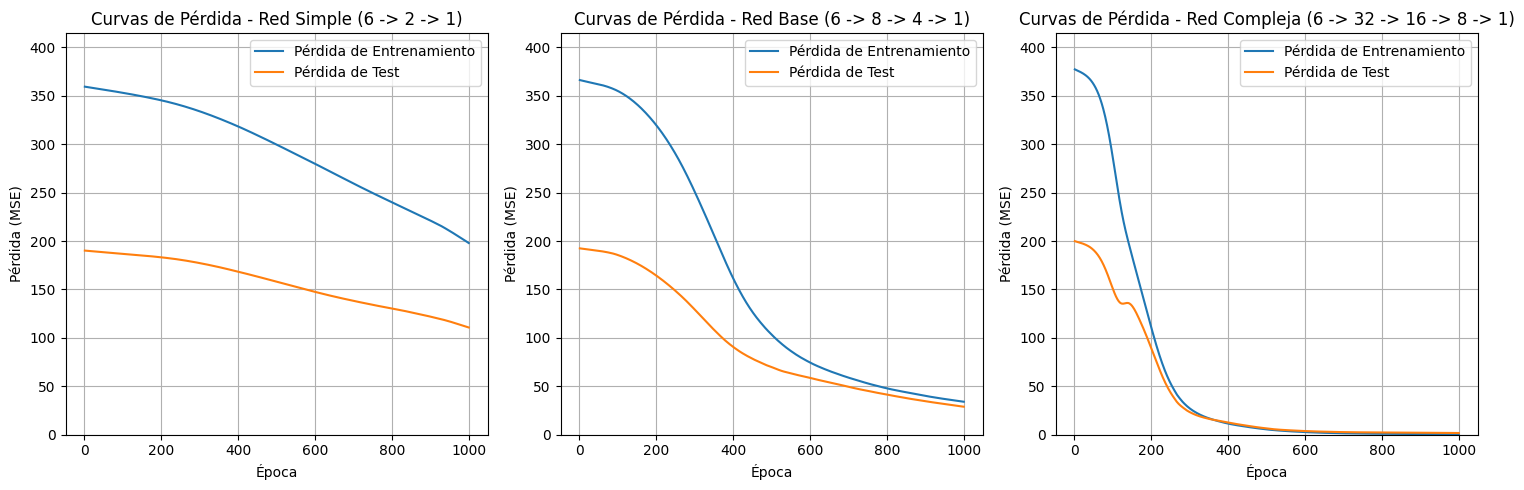

In [ ]:
import matplotlib.pyplot as plt

# Obtener el máximo valor de pérdida para establecer una escala uniforme en los gráficos
max_loss = max(
    max(simple_train_losses + simple_test_losses),
    max(base_train_losses + base_test_losses),
    max(complex_train_losses + complex_test_losses)
)

architectures = {
    "Red Simple (6 -> 2 -> 1)": {
        "train": simple_train_losses,
        "test": simple_test_losses
    },
    "Red Base (6 -> 8 -> 4 -> 1)": {
        "train": base_train_losses,
        "test": base_test_losses
    },
    "Red Compleja (6 -> 32 -> 16 -> 8 -> 1)": {
        "train": complex_train_losses,
        "test": complex_test_losses
    }
}

n_epochs = len(simple_train_losses)  # Las tres arquitecturas fueron entrenadas durante la misma cantidad de épocas
epochs = range(1, n_epochs + 1)

plt.figure(figsize=(15, 5)) # Figura para todos los gráficos para control de escala

for i, (name, losses) in enumerate(architectures.items()):
    plt.subplot(1, 3, i + 1) # Crear un subplot para cada arquitectura
    plt.plot(epochs, losses["train"], label="Pérdida de Entrenamiento")
    plt.plot(epochs, losses["test"], label="Pérdida de Test")
    plt.title(f"Curvas de Pérdida - {name}")
    plt.xlabel("Época")
    plt.ylabel("Pérdida (MSE)")
    plt.legend()
    plt.grid(True)
    plt.ylim(0, max_loss * 1.1) # Mantener la misma escala en el eje Y

plt.tight_layout()
plt.show()

**Explicación general proporcionada por Gemini a partir del prompt anterior:**
### Patrones en las curvas de pérdida de entrenamiento y test

- **Underfitting (subajuste):** ocurre cuando el modelo es demasiado simple para capturar las relaciones presentes en los datos. En las curvas de pérdida, esto suele observarse cuando tanto la pérdida de entrenamiento como la de test se mantienen relativamente altas y no disminuyen de manera significativa. Ambas curvas suelen permanecer cercanas entre sí.

- **Overfitting (sobreajuste):** ocurre cuando el modelo aprende en exceso los datos de entrenamiento y pierde capacidad de generalización. Puede observarse cuando la pérdida de entrenamiento continúa disminuyendo, mientras que la pérdida de test deja de mejorar, se estanca o comienza a aumentar.

- **Buen ajuste:** se observa cuando las pérdidas de entrenamiento y test disminuyen y se estabilizan en valores bajos, sin una separación excesiva entre ambas curvas.

In [ ]:
print("Red simple")
print("Train final:", simple_train_losses[-1])
print("Test final:", simple_test_losses[-1])
print("Mínimo test:", min(simple_test_losses))
print("Época mínimo test:", simple_test_losses.index(min(simple_test_losses)) + 1)

print("\nRed base")
print("Train final:", base_train_losses[-1])
print("Test final:", base_test_losses[-1])
print("Mínimo test:", min(base_test_losses))
print("Época mínimo test:", base_test_losses.index(min(base_test_losses)) + 1)

print("\nRed compleja")
print("Train final:", complex_train_losses[-1])
print("Test final:", complex_test_losses[-1])
print("Mínimo test:", min(complex_test_losses))
print("Época mínimo test:", complex_test_losses.index(min(complex_test_losses)) + 1)

Red simple
Train final: 197.89889526367188
Test final: 110.70800018310547
Mínimo test: 110.70800018310547
Época mínimo test: 1000

Red base
Train final: 34.04747772216797
Test final: 28.924789428710938
Mínimo test: 28.924789428710938
Época mínimo test: 1000

Red compleja
Train final: 0.5743861794471741
Test final: 1.77752685546875
Mínimo test: 1.77752685546875
Época mínimo test: 1000


### Experimento adicional para observar posible overfitting

En la comparación anterior, la red compleja continuó reduciendo tanto la pérdida de entrenamiento como la de test hasta la última época, por lo que no se observó un patrón claro de overfitting.

Para profundizar el análisis, se realizará un experimento adicional con una red de mayor capacidad y una mayor cantidad de épocas, manteniendo los mismos datos de entrenamiento y test.

El objetivo no es asumir que necesariamente aparecerá overfitting, sino observar si al aumentar la capacidad y prolongar el entrenamiento comienza a generarse una separación entre las curvas de entrenamiento y test.

### Prompt utilizado en Gemini

> Ya realicé un experimento comparando tres arquitecturas durante 1000 épocas. La red más compleja fue 6 → 32 → 16 → 8 → 1 y no mostró un patrón claro de overfitting: tanto la pérdida de entrenamiento como la de test continuaron disminuyendo hasta la última época.
> Quiero realizar un experimento adicional para investigar si aparece overfitting.
> Necesito que:
> 1. definas una nueva red neuronal de mayor capacidad con arquitectura 6 → 64 → 32 → 16 → 8 → 1;
> 2. utilices ReLU en las capas ocultas y ninguna activación en la salida;
> 3. uses los mismos tensores X_train_tensor, y_train_tensor, X_test_tensor y y_test_tensor;
> 4. utilices torch.manual_seed(42);
> 5. mantengas MSELoss y Adam con lr=0.001;
> 6. entrenes durante 3000 épocas;
> 7. registres en cada época la pérdida de entrenamiento y test utilizando el mismo estado del modelo después de actualizar los parámetros;
> 8. evalúes train y test con torch.no_grad() después de cada actualización;
> 9. devuelvas las listas de pérdidas para poder graficarlas posteriormente.
> No modifiques los conjuntos de datos, no calcules todavía R² ni MAE, no generes gráficos y no saques conclusiones sobre overfitting. Quiero analizar los resultados por separado después.

In [ ]:
import torch
import torch.nn as nn

# Definición de una arquitectura de mayor capacidad
# Arquitectura: 6 -> 64 -> 32 -> 16 -> 8 -> 1
class HighCapacityNetwork(nn.Module):
    def __init__(self):
        super(HighCapacityNetwork, self).__init__()
        self.fc1 = nn.Linear(6, 64)
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, 16)
        self.fc4 = nn.Linear(16, 8)
        self.fc5 = nn.Linear(8, 1)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = torch.relu(self.fc3(x))
        x = torch.relu(self.fc4(x))
        x = self.fc5(x)
        return x

# Crear y entrenar el modelo de mayor capacidad
torch.manual_seed(42) # Para reproducibilidad
high_capacity_model = HighCapacityNetwork()
print("\n--- Entrenando Red de Mayor Capacidad ---")
high_capacity_train_losses, high_capacity_test_losses = train_model(
    high_capacity_model, X_train_tensor, y_train_tensor, X_test_tensor, y_test_tensor, n_epochs=3000
)

print("\nLas pérdidas de entrenamiento y test para el modelo de mayor capacidad han sido registradas.")


--- Entrenando Red de Mayor Capacidad ---
Entrenamiento finalizado para HighCapacityNetwork.

Las pérdidas de entrenamiento y test para el modelo de mayor capacidad han sido registradas.


In [ ]:
print("Train final:", high_capacity_train_losses[-1])
print("Test final:", high_capacity_test_losses[-1])
print("Mínimo test:", min(high_capacity_test_losses))
print(
    "Época mínimo test:",
    high_capacity_test_losses.index(min(high_capacity_test_losses)) + 1
)

Train final: 0.0012238804483786225
Test final: 0.4451761841773987
Mínimo test: 0.43930208683013916
Época mínimo test: 2534


### Prompt utilizado en Gemini

> Tengo registradas las pérdidas del modelo de mayor capacidad en:
>
> - `high_capacity_train_losses`
> - `high_capacity_test_losses`
>
> El modelo fue entrenado durante 3000 épocas.
>
> Quiero visualizar la evolución de ambas pérdidas para analizar si aparece overfitting.
>
> Generá un único gráfico que muestre:
>
> - pérdida de entrenamiento;
> - pérdida de test;
> - las 3000 épocas en el eje X;
> - MSE en el eje Y;
> - título, etiquetas de ejes, leyenda y grilla.
>
> Además, marcá visualmente la época en la que la pérdida de test alcanza su valor mínimo.
>
> No vuelvas a entrenar el modelo, no calcules métricas adicionales y no redactes conclusiones sobre los resultados.

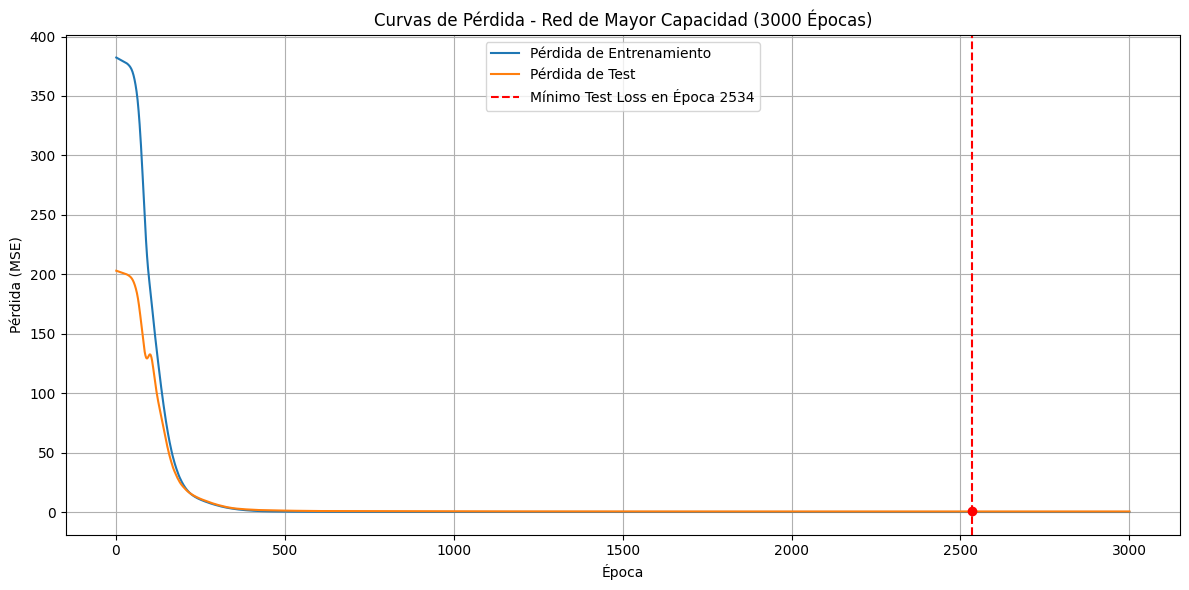

In [ ]:
import matplotlib.pyplot as plt

# Número de épocas
n_epochs_high_capacity = len(high_capacity_train_losses)
epochs_high_capacity = range(1, n_epochs_high_capacity + 1)

# Encontrar la época con la pérdida de test mínima
min_test_loss_value = min(high_capacity_test_losses)
min_test_loss_epoch = high_capacity_test_losses.index(min_test_loss_value) + 1

plt.figure(figsize=(12, 6))
plt.plot(epochs_high_capacity, high_capacity_train_losses, label="Pérdida de Entrenamiento")
plt.plot(epochs_high_capacity, high_capacity_test_losses, label="Pérdida de Test")
plt.axvline(
    x=min_test_loss_epoch,
    color='r',
    linestyle='--',
    label=f'Mínimo Test Loss en Época {min_test_loss_epoch}'
)
plt.scatter(min_test_loss_epoch, min_test_loss_value, color='red', marker='o', zorder=5)

plt.title("Curvas de Pérdida - Red de Mayor Capacidad (3000 Épocas)")
plt.xlabel("Época")
plt.ylabel("Pérdida (MSE)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

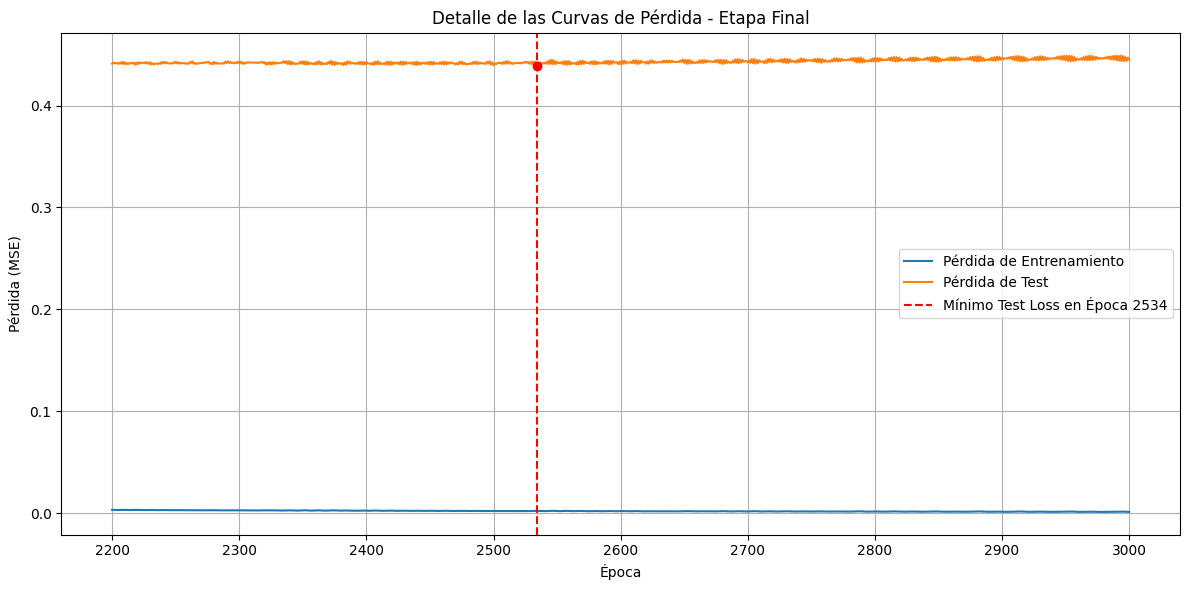

In [ ]:
# Zoom sobre la etapa final del entrenamiento
start_epoch = 2200

plt.figure(figsize=(12, 6))

plt.plot(
    range(start_epoch, n_epochs_high_capacity + 1),
    high_capacity_train_losses[start_epoch - 1:],
    label="Pérdida de Entrenamiento"
)

plt.plot(
    range(start_epoch, n_epochs_high_capacity + 1),
    high_capacity_test_losses[start_epoch - 1:],
    label="Pérdida de Test"
)

plt.axvline(
    x=min_test_loss_epoch,
    color='r',
    linestyle='--',
    label=f'Mínimo Test Loss en Época {min_test_loss_epoch}'
)

plt.scatter(
    min_test_loss_epoch,
    min_test_loss_value,
    color='red',
    marker='o',
    zorder=5
)

plt.title("Detalle de las Curvas de Pérdida - Etapa Final")
plt.xlabel("Época")
plt.ylabel("Pérdida (MSE)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Interpretación del experimento de mayor capacidad

La red de mayor capacidad logró reducir fuertemente la pérdida de entrenamiento y de test. Sin embargo, al observar el tramo final del entrenamiento aparece una señal de **overfitting**.

La pérdida de test alcanzó su valor mínimo en la época **2534**, con un MSE aproximado de **0.4393**. A partir de ese punto, la pérdida de entrenamiento continuó disminuyendo hasta valores cercanos a cero, mientras que la pérdida de test dejó de mejorar y comenzó a aumentar levemente.

Esto indica que, después de cierta cantidad de épocas, el modelo continúa ajustándose a los datos de entrenamiento sin obtener una mejora equivalente sobre los datos de test.

### Conclusión de la experimentación con distintas arquitecturas

La comparación entre arquitecturas mostró comportamientos diferentes según la capacidad de la red.

La **red simple (6 → 2 → 1)** presentó un claro subajuste, ya que mantuvo pérdidas elevadas tanto en entrenamiento como en test.

La **red base (6 → 8 → 4 → 1)** logró reducir considerablemente ambas pérdidas y mantuvo un comportamiento estable entre entrenamiento y test, mostrando una mejor capacidad para representar el problema.

La **red de mayor capacidad (6 → 64 → 32 → 16 → 8 → 1)** alcanzó errores muy bajos, pero al prolongar el entrenamiento hasta 3000 épocas apareció una señal de sobreajuste: luego de la época 2534 la pérdida de test dejó de mejorar y comenzó a aumentar levemente, mientras que la pérdida de entrenamiento continuó en valores cercanos a cero.

Estos resultados muestran que aumentar la capacidad de una red puede mejorar su ajuste, pero también puede favorecer el overfitting si el entrenamiento se prolonga demasiado.

## 6. Comparación con los modelos utilizados en Aprendizaje Automático I

Para evaluar el desempeño de la red neuronal desarrollada en PyTorch, se compararán sus resultados con los obtenidos previamente en Aprendizaje Automático I utilizando el mismo dataset.

La comparación se realizará sobre el conjunto de test y utilizando las mismas métricas empleadas anteriormente: **MSE, MAE y R²**.

Se utilizará como referencia la arquitectura base de la red neuronal, ya que presentó un buen equilibrio entre error de entrenamiento y test sin mostrar un sobreajuste marcado.

### Prompt utilizado en Gemini

> Ya tengo evaluada mi red neuronal base en PyTorch y también dispongo de los resultados obtenidos previamente en Aprendizaje Automático I.
>
> Quiero comparar ambos modelos utilizando las métricas del conjunto de test: MSE, MAE y R².
>
> Los resultados de AA1 fueron:
>
> - MSE test: 67.6026
> - MAE test: 6.8075
> - R² test: 0.5450
>
> Los resultados de la red neuronal base en PyTorch fueron:
>
> - MSE test: 28.9248
> - MAE test: 3.6631
> - R² test: 0.8053
>
> Generá únicamente una tabla comparativa clara utilizando estos valores.
>
> No recalcules métricas, no entrenes modelos nuevamente y no redactes todavía conclusiones sobre cuál modelo es mejor.

In [ ]:
import pandas as pd

# Resultados de Aprendizaje Automático I (Regresión Lineal)
aa1_metrics = {
    'Modelo': 'Regresión Lineal (AA1)',
    'MSE Test': 67.6026,
    'MAE Test': 6.8075,
    'R² Test': 0.5450
}

# Resultados de la Red Neuronal Base (PyTorch)
pytorch_metrics = {
    'Modelo': 'Red Neuronal Base (PyTorch)',
    'MSE Test': 28.9248,
    'MAE Test': 3.6631,
    'R² Test': 0.8053
}

# Crear DataFrame para la comparación
comparison_df = pd.DataFrame([aa1_metrics, pytorch_metrics])

comparison_df

,Modelo,MSE Test,MAE Test,R² Test
0,Regresión Lineal (AA1),67.6026,6.8075,0.5450
1,Red Neuronal Base (PyTorch),28.9248,3.6631,0.8053


### Análisis de la comparación con Aprendizaje Automático I

La red neuronal base obtuvo mejores resultados que la regresión lineal utilizada en Aprendizaje Automático I: presentó menores valores de **MSE** y **MAE**, y un **R²** más alto en el conjunto de test.

Esto indica que la red neuronal logró realizar predicciones más precisas y explicar una mayor proporción de la variabilidad de la resistencia residual.

Una posible explicación es que la regresión lineal modela relaciones lineales entre las variables, mientras que la red neuronal incorpora capas ocultas y funciones de activación ReLU, lo que le permite representar relaciones más complejas y no lineales.

Para este conjunto de datos, la red neuronal base mostró un mejor desempeño predictivo que el modelo lineal utilizado previamente.

## 7. Conclusiones, aprendizajes y dificultades

### Conclusiones generales

En este trabajo práctico se implementó una red neuronal para resolver el mismo problema de regresión utilizado previamente en Aprendizaje Automático I.

La red neuronal base logró un mejor desempeño que la regresión lineal utilizada anteriormente, obteniendo menores valores de MSE y MAE y un mayor valor de R² sobre el conjunto de test.

También se observó cómo la capacidad de la red influye en su comportamiento. Una arquitectura demasiado simple presentó underfitting, mientras que una arquitectura de mayor capacidad logró errores muy bajos pero comenzó a mostrar señales de overfitting al prolongar el entrenamiento.

### Aprendizajes

Uno de los principales aprendizajes fue comprender el ciclo completo de entrenamiento de una red neuronal en PyTorch: realizar la predicción, calcular la pérdida, obtener los gradientes mediante `backward()` y actualizar los parámetros con el optimizador.

También fue importante diferenciar el comportamiento del modelo durante entrenamiento y evaluación, y analizar conjuntamente las pérdidas de train y test para entender si el modelo está aprendiendo de forma adecuada o si aparecen problemas de underfitting u overfitting.

Otro aprendizaje fue comprobar que una red más grande no necesariamente implica automáticamente un mejor modelo. La capacidad de la arquitectura y la cantidad de épocas deben analizarse en conjunto con el comportamiento sobre datos que el modelo no utilizó para actualizar sus parámetros.

### Dificultades, errores y soluciones aplicadas

Durante la experimentación se detectó que la primera propuesta generada por Gemini registraba la pérdida de entrenamiento antes de actualizar los parámetros, mientras que la pérdida de test se calculaba después de la actualización.

Para hacer comparables ambas curvas, se modificó la función de entrenamiento para calcular las pérdidas de entrenamiento y test utilizando el mismo estado del modelo, luego de realizar la actualización de los parámetros.

Otra dificultad apareció al intentar visualizar el overfitting de la red de mayor capacidad. En el gráfico completo de las 3000 épocas, las pérdidas iniciales eran mucho mayores y hacían que la parte final de las curvas quedara prácticamente pegada al eje X.

Para resolverlo se realizó un segundo gráfico con un zoom sobre las últimas épocas, sin modificar ni recalcular los resultados. Esto permitió observar con mayor claridad que la pérdida de test alcanzaba un mínimo y luego comenzaba a aumentar levemente, mientras la pérdida de entrenamiento continuaba en valores cercanos a cero.

### Reflexión final

El trabajo permitió pasar de utilizar un modelo ya disponible a construir y analizar una red neuronal de manera más consciente, entendiendo no solamente cómo entrenarla sino también cómo interpretar su comportamiento.

El uso de IA generativa se utilizó como apoyo para proponer código y explicaciones, pero las respuestas fueron revisadas antes de ejecutarlas y se realizaron modificaciones cuando fue necesario para mantener consistencia metodológica y comprender cada parte del proceso.

## 8. Referencias y herramientas utilizadas

- **PyTorch:** utilizado para la definición, entrenamiento y evaluación de las redes neuronales.
- **Scikit-learn:** utilizado para el cálculo de métricas de regresión y para reutilizar el preprocesamiento realizado en Aprendizaje Automático I.
- **Pandas:** utilizado para el manejo y presentación de datos.
- **Matplotlib:** utilizado para la visualización de las curvas de pérdida.
- **Yacht Hydrodynamics Dataset:** conjunto de datos utilizado originalmente en Aprendizaje Automático I y reutilizado en este trabajo.
- **Gemini en Google Colab:** utilizado como herramienta de apoyo para la generación de propuestas de código y explicaciones. Los prompts utilizados se encuentran documentados dentro del notebook.
- **ChatGPT:** se utilizó como herramienta de apoyo para la interpretación de resultados, revisión de explicaciones teóricas y discusión de decisiones metodológicas durante el desarrollo del trabajo.